# Ames Housing and Tornado Data

The housing data is loaded into `homes_df`, with year fields kept as strings. The expanded tornado data is loaded into `tornadoes_df`; the summaries below focus on records from 2005 through 2010.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display

# Keep summary values readable without decimals or scientific notation.
pd.options.display.float_format = "{:,.0f}".format

In [2]:
# Locate the project folder when Jupyter starts in the repository or analysis folder.
project_root = next(
    (candidate for candidate in (Path.cwd(), *Path.cwd().parents)
     if (candidate / "analysis" / "AmesHousing-working.csv").exists()),
    None,
)
if project_root is None:
    raise FileNotFoundError("Could not find analysis/AmesHousing-working.csv from the current directory.")

housing_path = project_root / "analysis" / "AmesHousing-working.csv"
year_columns = ["Year Built", "Year Remod/Add", "Garage Yr Blt", "Yr Sold"]
homes_df = pd.read_csv(
    housing_path,
    dtype={column: "string" for column in year_columns},
)

print(f"Loaded {homes_df.shape[0]:,} homes and {homes_df.shape[1]} columns.")

Loaded 2,884 homes and 82 columns.


## Numeric summary statistics

Year columns are strings, so they are excluded from this numeric summary.

In [3]:
numeric_summary = homes_df.describe().T
display(numeric_summary)

,count,mean,std,min,25%,50%,75%,max
Order,"2,884","1,465",848,1,731,"1,462","2,200","2,930"
PID,"2,884","715,446,241","188,740,444","526,301,100","528,480,085","535,455,070","907,181,092","1,007,100,110"
MS SubClass,"2,884",58,43,20,20,50,70,190
Lot Frontage,"2,402",69,23,21,58,68,80,313
Lot Area,"2,884","10,107","7,854","1,300","7,413","9,402","11,513","215,245"
Overall Qual,"2,884",6,1,1,5,6,7,10
Overall Cond,"2,884",6,1,1,5,5,6,9
Mas Vnr Area,"2,884",101,178,0,0,0,164,"1,600"
BsmtFin SF 1,"2,884",441,449,0,0,370,734,"5,644"
BsmtFin SF 2,"2,884",50,170,0,0,0,0,"1,526"


## Sale price by basement presence

Compare sale prices for homes with and without a basement across the full housing dataset, regardless of sale month. Basement presence is defined as `Total Bsmt SF > 0`. The bootstrap interval estimates uncertainty in the median price difference; this is an unadjusted association and does not isolate a causal basement premium.

In [4]:
import numpy as np

basement_homes = homes_df.assign(
    HasBasement=homes_df["Total Bsmt SF"].fillna(0).gt(0)
)
with_basement = basement_homes.loc[basement_homes["HasBasement"], "SalePrice"].dropna().to_numpy()
without_basement = basement_homes.loc[~basement_homes["HasBasement"], "SalePrice"].dropna().to_numpy()

basement_price_summary = (
    basement_homes.groupby("HasBasement")["SalePrice"]
    .agg(SampleSize="count", MedianSalePrice="median")
    .rename(index={False: "No basement", True: "Basement"})
)
display(basement_price_summary)

observed_median_difference = np.median(with_basement) - np.median(without_basement)
rng = np.random.default_rng(42)
n_resamples = 10_000
batch_size = 250
bootstrap_differences = np.empty(n_resamples)
for start in range(0, n_resamples, batch_size):
    batch_n = min(batch_size, n_resamples - start)
    with_samples = with_basement[
        rng.integers(0, len(with_basement), size=(batch_n, len(with_basement)))
    ]
    without_samples = without_basement[
        rng.integers(0, len(without_basement), size=(batch_n, len(without_basement)))
    ]
    bootstrap_differences[start:start + batch_n] = (
        np.median(with_samples, axis=1) - np.median(without_samples, axis=1)
    )

ci_low, ci_high = np.percentile(bootstrap_differences, [2.5, 97.5])
median_difference_result = pd.DataFrame(
    {
        "Estimate": [observed_median_difference],
        "95% Bootstrap CI Lower": [ci_low],
        "95% Bootstrap CI Upper": [ci_high],
        "CI Excludes Zero": [ci_low > 0 or ci_high < 0],
    },
    index=["Median price: basement minus no basement"],
)
display(median_difference_result)
print(f"Median price difference (basement minus no basement): ${observed_median_difference:,.0f}")
print(f"95% bootstrap confidence interval: ${ci_low:,.0f} to ${ci_high:,.0f}")
print(f"The interval excludes zero: {ci_low > 0 or ci_high < 0}")

,SampleSize,MedianSalePrice
HasBasement,,
No basement,77,"100,000"
Basement,2807,"162,000"


,Estimate,95% Bootstrap CI Lower,95% Bootstrap CI Upper,CI Excludes Zero
Median price: basement minus no basement,"62,000","52,000","67,841",True


Median price difference (basement minus no basement): $62,000
95% bootstrap confidence interval: $52,000 to $67,841
The interval excludes zero: True


## Monthly sales time series

Track the average sale price and number of recorded sales chronologically, one year-month period at a time across the full housing dataset.

In [5]:
sales_by_time = (
    homes_df.assign(
        SaleMonth=pd.to_datetime(
            homes_df["Yr Sold"] + "-"
            + homes_df["Mo Sold"].astype("string").str.zfill(2) + "-01",
            format="%Y-%m-%d",
            errors="coerce",
        )
    )
    .groupby("SaleMonth")
    .agg(
        AverageSalePrice=("SalePrice", "mean"),
        NumberOfSales=("SalePrice", "count"),
    )
    .sort_index()
    .asfreq("MS")
)
sales_by_time["NumberOfSales"] = sales_by_time["NumberOfSales"].fillna(0).astype("int64")
print(f"Monthly series: {sales_by_time.index.min():%b %Y} to {sales_by_time.index.max():%b %Y}")
display(sales_by_time.head(10))

Monthly series: Jan 2006 to Jul 2010


,AverageSalePrice,NumberOfSales
SaleMonth,,
2006-01-01,"202,997",18
2006-02-01,"188,707",23
2006-03-01,"182,009",51
2006-04-01,"159,750",47
2006-05-01,"169,166",75
2006-06-01,"174,234",97
2006-07-01,"177,271",121
2006-08-01,"202,379",45
2006-09-01,"210,055",39


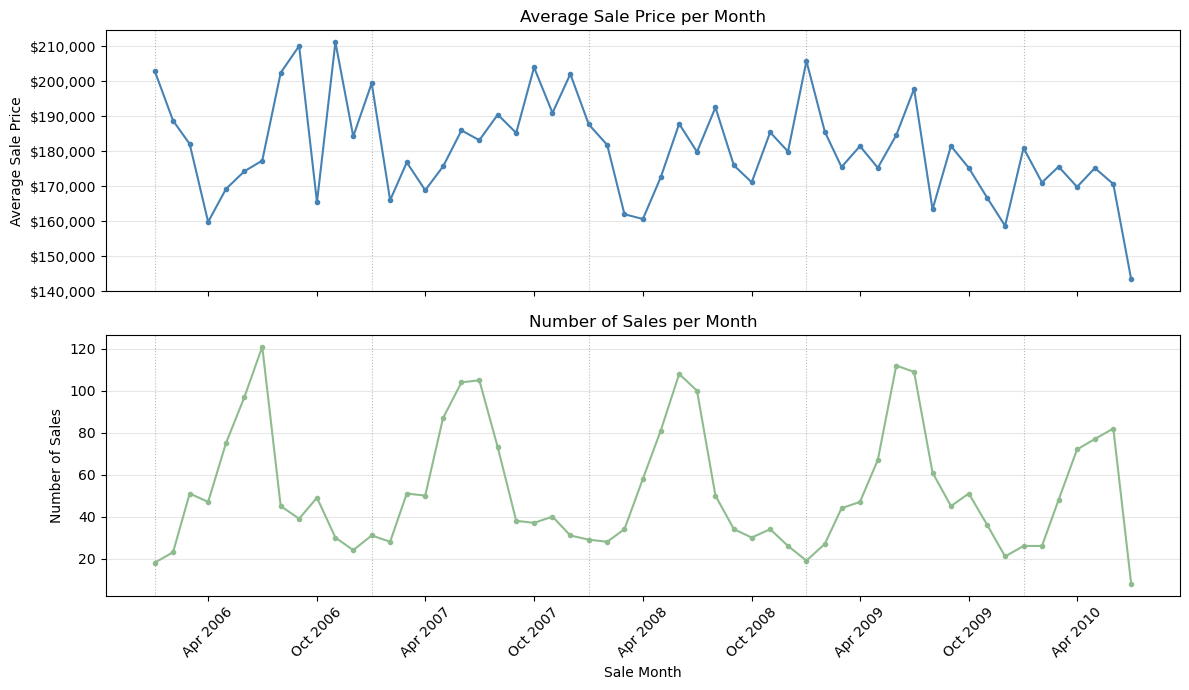

In [6]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

axes[0].plot(
    sales_by_time.index,
    sales_by_time["AverageSalePrice"],
    marker="o",
    markersize=3,
    color="steelblue",
)
axes[0].set_title("Average Sale Price per Month")
axes[0].set_ylabel("Average Sale Price")
axes[0].yaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
axes[0].grid(axis="y", alpha=0.3)

axes[1].plot(
    sales_by_time.index,
    sales_by_time["NumberOfSales"],
    marker="o",
    markersize=3,
    color="darkseagreen",
)
axes[1].set_title("Number of Sales per Month")
axes[1].set_xlabel("Sale Month")
axes[1].set_ylabel("Number of Sales")
axes[1].yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
axes[1].xaxis.set_major_locator(mdates.MonthLocator(interval=6))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
for year in range(sales_by_time.index.min().year, sales_by_time.index.max().year + 1):
    for ax in axes:
        ax.axvline(
            pd.Timestamp(year=year, month=1, day=1),
            color="gray",
            linestyle=":",
            linewidth=0.8,
            alpha=0.55,
        )
for ax in axes:
    ax.grid(axis="y", alpha=0.3)
    ax.tick_params(axis="x", rotation=45)
fig.tight_layout()
plt.show()

In [7]:
# Load the expanded seven-county tornado dataset. Keep the year column as strings.
tornado_path = project_root / "analysis" / "Iowa-central-counties-tornadoes-working.csv"
tornadoes_df = pd.read_csv(tornado_path, dtype={"Year": "string"})
month_numbers = {
    "January": 1, "February": 2, "March": 3, "April": 4,
    "May": 5, "June": 6, "July": 7, "August": 8,
    "September": 9, "October": 10, "November": 11, "December": 12,
}
tornadoes_df["Mo"] = tornadoes_df["Month"].map(month_numbers).astype("int64")

years_of_interest = {str(year) for year in range(2005, 2011)}
tornadoes_2005_2010_df = tornadoes_df.loc[
    tornadoes_df["Year"].isin(years_of_interest)
].copy()

print(f"Loaded {len(tornadoes_df):,} tornado records across all years.")
print(f"Records from 2005 to 2010: {len(tornadoes_2005_2010_df):,}")
print("Tornado counts by month in the selected data:")
display(tornadoes_2005_2010_df["Mo"].value_counts().sort_index().to_frame("Tornado Count"))

Loaded 435 tornado records across all years.
Records from 2005 to 2010: 37
Tornado counts by month in the selected data:


,Tornado Count
Mo,
3,1
4,2
5,1
6,13
7,4
9,2
10,1
11,13


## Tornado summary statistics, 2005 to 2010

These summaries use only tornado records in the selected years. County counts and intensity counts show how the records are distributed within that period.

In [8]:
tornado_count_by_month = (
    tornadoes_2005_2010_df.groupby("Mo")["EventID"]
    .nunique()
    .reindex(range(1, 13), fill_value=0)
    .rename("Tornado Count")
    .to_frame()
)
display(tornado_count_by_month)

display(
    tornadoes_2005_2010_df["Intensity"]
    .value_counts(dropna=False)
    .rename_axis("Intensity")
    .to_frame("Tornado Count")
)

,Tornado Count
Mo,
1,0
2,0
3,1
4,2
5,1
6,13
7,4
8,0
9,2


,Tornado Count
Intensity,
EF0,14
F0,8
F1,6
EF1,5
F2,2
F3,1
EF2,1


In [9]:
impact_columns = [
    "PropertyDamageUSD", "CropDamageUSD",
    "TornadoLengthMiles", "TornadoWidthYards",
]
tornado_impact_summary = tornadoes_2005_2010_df[impact_columns].describe().T
display(tornado_impact_summary)

,count,mean,std,min,25%,50%,75%,max
PropertyDamageUSD,37,"426,135","1,917,477",0,0,"25,000","100,000","11,700,000"
CropDamageUSD,37,"14,243","82,099",0,0,0,0,"500,000"
TornadoLengthMiles,37,3,4,0,0,1,3,14
TornadoWidthYards,37,89,200,20,30,30,75,"1,250"


## Monthly tornado frequency time series

Count tornadoes chronologically by year-month for 2005 through 2010, filling months with no tornadoes as zero.

In [10]:
tornadoes_2005_2010_df = tornadoes_2005_2010_df.assign(
    EventMonth=pd.to_datetime(
        tornadoes_2005_2010_df["Year"] + "-"
        + tornadoes_2005_2010_df["Mo"].astype("string").str.zfill(2) + "-01",
        format="%Y-%m-%d",
        errors="coerce",
    )
)

tornado_frequency_by_time = (
    tornadoes_2005_2010_df.groupby("EventMonth")["EventID"]
    .nunique()
    .rename("Tornado Count")
    .to_frame()
    .sort_index()
    .asfreq("MS", fill_value=0)
)
tornado_frequency_by_time["Tornado Count"] = (
    tornado_frequency_by_time["Tornado Count"].fillna(0).astype("int64")
)
print(
    f"Monthly series: {tornado_frequency_by_time.index.min():%b %Y} "
    f"to {tornado_frequency_by_time.index.max():%b %Y}"
)
display(tornado_frequency_by_time)

Monthly series: Mar 2005 to Jun 2010


,Tornado Count
EventMonth,
2005-03-01,1
2005-04-01,0
2005-05-01,1
2005-06-01,0
2005-07-01,0
...,...
2010-02-01,0
2010-03-01,0
2010-04-01,0


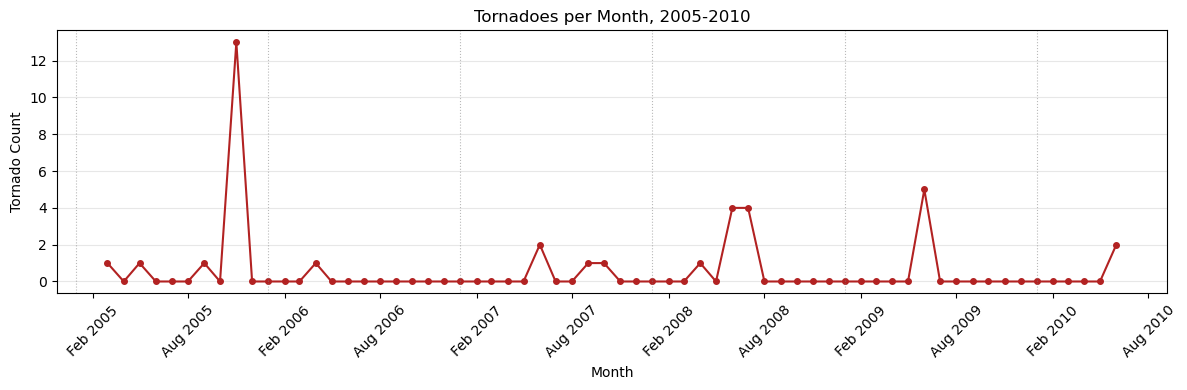

In [11]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(
    tornado_frequency_by_time.index,
    tornado_frequency_by_time["Tornado Count"],
    marker="o",
    markersize=4,
    color="firebrick",
)
ax.set_title("Tornadoes per Month, 2005-2010")
for year in range(
    tornado_frequency_by_time.index.min().year,
    tornado_frequency_by_time.index.max().year + 1,
):
    ax.axvline(
        pd.Timestamp(year=year, month=1, day=1),
        color="gray",
        linestyle=":",
        linewidth=0.8,
        alpha=0.55,
    )
ax.set_xlabel("Month")
ax.set_ylabel("Tornado Count")
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.grid(axis="y", alpha=0.3)
ax.tick_params(axis="x", rotation=45)
fig.tight_layout()
plt.show()

## Monthly housing and tornado comparison

The three panels share one monthly timeline from 2005 through 2010. Housing values are left blank for 2005, and each panel keeps its own scale so the different measures remain readable.

In [12]:
comparison_months = pd.date_range("2006-01-01", "2010-07-01", freq="MS")
comparison_by_time = pd.DataFrame(index=comparison_months)
comparison_by_time["AverageSalePrice"] = sales_by_time["AverageSalePrice"].reindex(comparison_months)
comparison_by_time["NumberOfSales"] = sales_by_time["NumberOfSales"].reindex(comparison_months)
comparison_by_time["TornadoCount"] = tornado_frequency_by_time["Tornado Count"].reindex(
    comparison_months, fill_value=0
)
comparison_by_time.loc[
    comparison_by_time.index.year == 2005,
    ["AverageSalePrice", "NumberOfSales"],
] = float("nan")

display(comparison_by_time.head(10))

,AverageSalePrice,NumberOfSales,TornadoCount
2006-01-01,"202,997",18,0
2006-02-01,"188,707",23,0
2006-03-01,"182,009",51,0
2006-04-01,"159,750",47,1
2006-05-01,"169,166",75,0
2006-06-01,"174,234",97,0
2006-07-01,"177,271",121,0
2006-08-01,"202,379",45,0
2006-09-01,"210,055",39,0
2006-10-01,"165,379",49,0


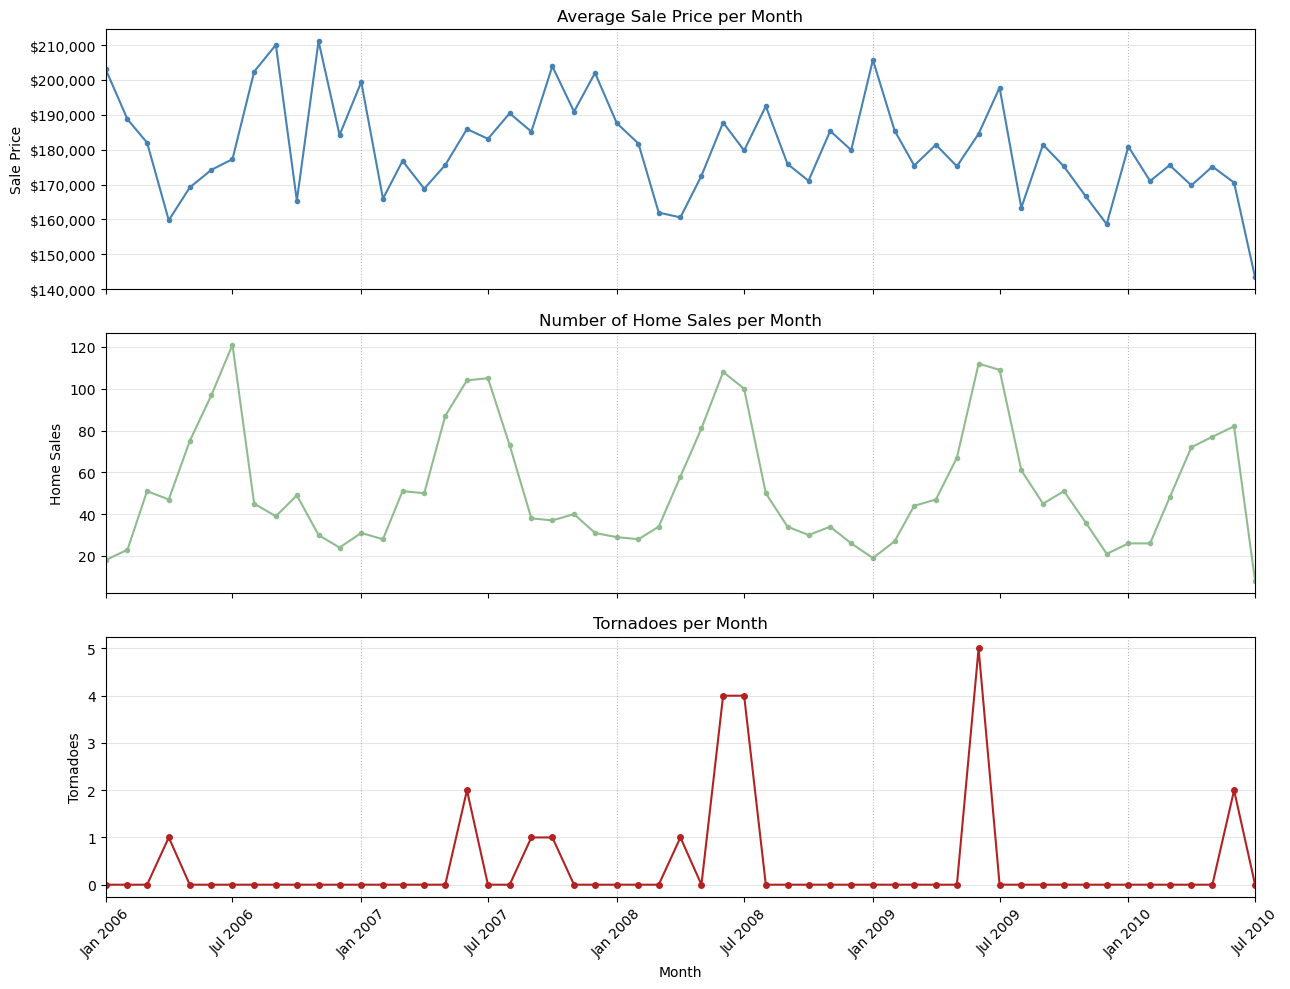

In [13]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

fig, axes = plt.subplots(3, 1, figsize=(13, 10), sharex=True)
axes[0].plot(
    comparison_by_time.index,
    comparison_by_time["AverageSalePrice"],
    marker="o",
    markersize=3,
    color="steelblue",
)
axes[0].set_title("Average Sale Price per Month")
axes[0].set_ylabel("Sale Price")
axes[0].yaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))

axes[1].plot(
    comparison_by_time.index,
    comparison_by_time["NumberOfSales"],
    marker="o",
    markersize=3,
    color="darkseagreen",
)
axes[1].set_title("Number of Home Sales per Month")
axes[1].set_ylabel("Home Sales")
axes[1].yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))

axes[2].plot(
    comparison_by_time.index,
    comparison_by_time["TornadoCount"],
    marker="o",
    markersize=4,
    color="firebrick",
)
axes[2].set_title("Tornadoes per Month")
axes[2].set_xlabel("Month")
axes[2].set_ylabel("Tornadoes")
axes[2].yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
axes[2].xaxis.set_major_locator(mdates.MonthLocator(interval=6))
axes[2].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))

for year in range(2005, 2011):
    for ax in axes:
        ax.axvline(
            pd.Timestamp(year=year, month=1, day=1),
            color="gray",
            linestyle=":",
            linewidth=0.8,
            alpha=0.55,
        )
for ax in axes:
    ax.set_xlim(comparison_months.min(), comparison_months.max())
    ax.grid(axis="y", alpha=0.3)
    ax.tick_params(axis="x", rotation=45)
fig.tight_layout()
plt.show()

## Basement purchases around tornado months

For each calendar month with at least one tornado in the seven-county dataset (2005-2010), compare Ames home purchases in the month before, the tornado month, and the month after. Multiple tornadoes in the same calendar month are treated as one tornado month. The basement purchase percentage and median sale price difference are descriptive, unadjusted comparisons; event windows can overlap when tornadoes occur in nearby months.

In [14]:
# Build one row per Ames sale and mark whether its total basement area is positive.
home_sales_for_tornado_windows = homes_df.assign(
    SaleMonth=pd.to_datetime(
        homes_df["Yr Sold"] + "-"
        + homes_df["Mo Sold"].astype("string").str.zfill(2) + "-01",
        format="%Y-%m-%d",
        errors="coerce",
    ),
    HasBasement=homes_df["Total Bsmt SF"].fillna(0).gt(0),
).dropna(subset=["SaleMonth", "SalePrice"])

# Use unique active calendar months so county clusters in one month do not repeat sales.
tornado_event_months = pd.DatetimeIndex(
    pd.to_datetime(
        tornadoes_2005_2010_df["Year"] + "-"
        + tornadoes_2005_2010_df["Mo"].astype("string").str.zfill(2) + "-01",
        format="%Y-%m-%d",
        errors="coerce",
    )
    .dropna()
    .drop_duplicates()
    .sort_values()
)

window_specs = [(-1, "Month before"), (0, "Tornado month"), (1, "Month after")]
window_sales = []
for offset, window_name in window_specs:
    for tornado_month in tornado_event_months:
        sale_month = tornado_month + pd.DateOffset(months=offset)
        matched_sales = home_sales_for_tornado_windows.loc[
            home_sales_for_tornado_windows["SaleMonth"].eq(sale_month)
        ].copy()
        if not matched_sales.empty:
            matched_sales["Window"] = window_name
            matched_sales["TornadoEventMonth"] = tornado_month
            window_sales.append(matched_sales)

if not window_sales:
    raise ValueError("No Ames home sales matched the tornado event windows.")

tornado_window_sales = pd.concat(window_sales, ignore_index=True)
window_summary_rows = []
for _, window_name in window_specs:
    window_data = tornado_window_sales.loc[tornado_window_sales["Window"].eq(window_name)]
    basement_prices = window_data.loc[window_data["HasBasement"], "SalePrice"]
    no_basement_prices = window_data.loc[~window_data["HasBasement"], "SalePrice"]
    median_with_basement = basement_prices.median()
    median_without_basement = no_basement_prices.median()
    window_summary_rows.append(
        {
            "Window": window_name,
            "Tornado Months Matched": window_data["TornadoEventMonth"].nunique(),
            "Home Purchases": len(window_data),
            "Basement Purchases": int(window_data["HasBasement"].sum()),
            "Purchases with Basement (%)": 100 * window_data["HasBasement"].mean(),
            "Purchases without Basement (%)": 100 * (~window_data["HasBasement"]).mean(),
            "Median Price with Basement": median_with_basement,
            "Median Price without Basement": median_without_basement,
            "Median Basement Price Difference": median_with_basement - median_without_basement,
        }
    )

tornado_window_summary = pd.DataFrame(window_summary_rows).set_index("Window")
display(tornado_window_summary)

,Tornado Months Matched,Home Purchases,Basement Purchases,Purchases with Basement (%),Purchases without Basement (%),Median Price with Basement,Median Price without Basement,Median Basement Price Difference
Window,,,,,,,,
Month before,9,616,605,98,2,"161,000","89,500","71,500"
Tornado month,9,686,660,96,4,"165,200","116,290","48,910"
Month after,9,605,590,98,2,"164,700","98,300","66,400"


## Tornado counts and purchases without a basement

Compare monthly tornado counts across the seven-county region with the percentage of Ames home purchases without a basement. The 2005 housing values remain blank because the housing dataset starts later. The summary contrasts housing months with at least one tornado and months with none; percentages are descriptive and do not establish that tornado activity caused a change in purchases.

In [15]:
# Aggregate unique tornado events by calendar month across the selected counties.
tornado_monthly_counts_for_mix = (
    tornadoes_2005_2010_df.assign(
        EventMonth=pd.to_datetime(
            tornadoes_2005_2010_df["Year"] + "-"
            + tornadoes_2005_2010_df["Mo"].astype("string").str.zfill(2) + "-01",
            format="%Y-%m-%d",
            errors="coerce",
        )
    )
    .groupby("EventMonth")["EventID"]
    .nunique()
    .rename("Tornado Count")
)

monthly_home_mix = (
    home_sales_for_tornado_windows.groupby("SaleMonth")
    .agg(
        HomePurchases=("SalePrice", "count"),
        PurchasesWithoutBasement=("HasBasement", lambda values: (~values).sum()),
    )
)
comparison_months = pd.date_range("2006-01-01", "2010-07-01", freq="MS")
tornado_vs_no_basement_by_month = pd.DataFrame(index=comparison_months)
tornado_vs_no_basement_by_month["Tornado Count"] = (
    tornado_monthly_counts_for_mix.reindex(comparison_months, fill_value=0).astype("int64")
)
tornado_vs_no_basement_by_month["Home Purchases"] = (
    monthly_home_mix["HomePurchases"].reindex(comparison_months).astype("Int64")
)
tornado_vs_no_basement_by_month["Purchases without Basement"] = (
    monthly_home_mix["PurchasesWithoutBasement"].reindex(comparison_months).astype("Int64")
)
tornado_vs_no_basement_by_month["Purchases without Basement (%)"] = (
    100 * tornado_vs_no_basement_by_month["Purchases without Basement"]
    / tornado_vs_no_basement_by_month["Home Purchases"]
)
tornado_vs_no_basement_by_month["Tornado Activity"] = (
    tornado_vs_no_basement_by_month["Tornado Count"]
    .gt(0)
    .map({True: "Tornado month", False: "No tornado"})
)
display(tornado_vs_no_basement_by_month)

observed_months = tornado_vs_no_basement_by_month.dropna(
    subset=["Purchases without Basement (%)"]
)
activity_summary_rows = []
for activity in ["No tornado", "Tornado month"]:
    activity_months = observed_months.loc[observed_months["Tornado Activity"].eq(activity)]
    total_purchases = int(activity_months["Home Purchases"].sum())
    no_basement_purchases = int(activity_months["Purchases without Basement"].sum())
    activity_summary_rows.append(
        {
            "Tornado Activity": activity,
            "Months": len(activity_months),
            "Tornadoes": int(activity_months["Tornado Count"].sum()),
            "Home Purchases": total_purchases,
            "Purchases without Basement": no_basement_purchases,
            "Pooled Purchases without Basement (%)": (
                100 * no_basement_purchases / total_purchases if total_purchases else float("nan")
            ),
            "Mean Monthly without-Basement (%)": activity_months[
                "Purchases without Basement (%)"
            ].mean(),
        }
    )
tornado_activity_mix_summary = pd.DataFrame(activity_summary_rows).set_index("Tornado Activity")
display(tornado_activity_mix_summary)

,Tornado Count,Home Purchases,Purchases without Basement,Purchases without Basement (%),Tornado Activity
2006-01-01,0,18,0,0,No tornado
2006-02-01,0,23,0,0,No tornado
2006-03-01,0,51,0,0,No tornado
2006-04-01,1,47,2,4,Tornado month
2006-05-01,0,75,3,4,No tornado
2006-06-01,0,97,4,4,No tornado
2006-07-01,0,121,3,2,No tornado
2006-08-01,0,45,1,2,No tornado
2006-09-01,0,39,0,0,No tornado
2006-10-01,0,49,2,4,No tornado


,Months,Tornadoes,Home Purchases,Purchases without Basement,Pooled Purchases without Basement (%),Mean Monthly without-Basement (%)
Tornado Activity,,,,,,
No tornado,46,0,2198,51,2,2
Tornado month,9,21,686,26,4,3


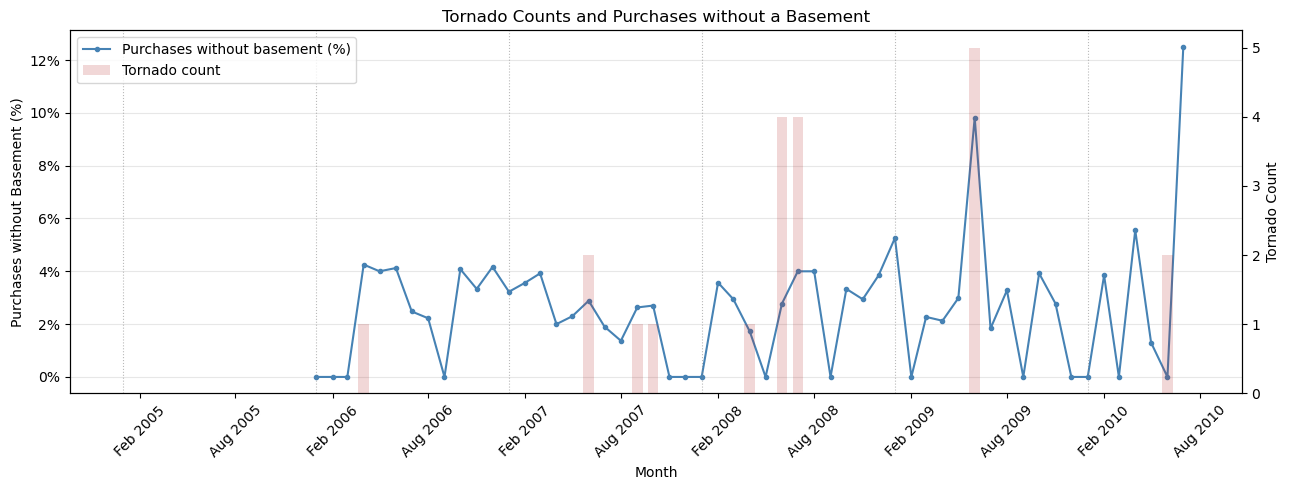

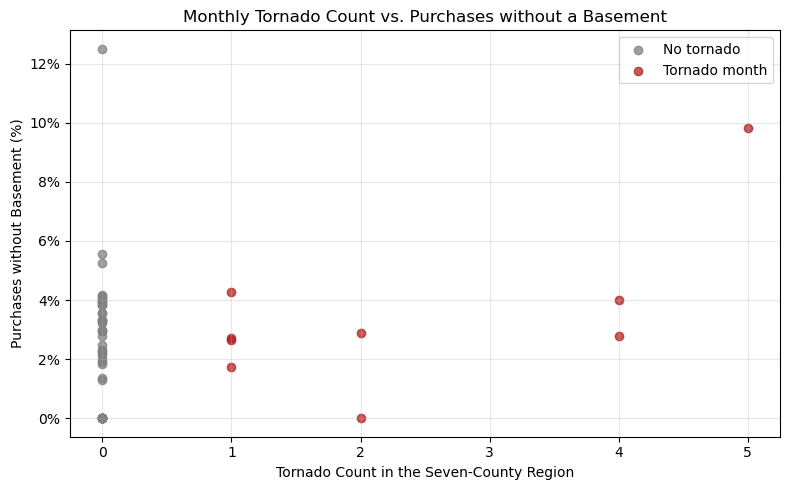

In [16]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

fig, ax_price_share = plt.subplots(figsize=(13, 5))
ax_tornado_count = ax_price_share.twinx()
ax_tornado_count.bar(
    tornado_vs_no_basement_by_month.index,
    tornado_vs_no_basement_by_month["Tornado Count"],
    width=20,
    color="firebrick",
    alpha=0.18,
    label="Tornado count",
)
ax_price_share.plot(
    tornado_vs_no_basement_by_month.index,
    tornado_vs_no_basement_by_month["Purchases without Basement (%)"],
    marker="o",
    markersize=3,
    color="steelblue",
    label="Purchases without basement (%)",
)
ax_price_share.set_title("Tornado Counts and Purchases without a Basement")
ax_price_share.set_ylabel("Purchases without Basement (%)")
ax_tornado_count.set_ylabel("Tornado Count")
ax_price_share.set_xlabel("Month")
ax_price_share.yaxis.set_major_formatter(StrMethodFormatter("{x:.0f}%"))
ax_tornado_count.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax_price_share.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
ax_price_share.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
for year in range(2005, 2011):
    ax_price_share.axvline(
        pd.Timestamp(year=year, month=1, day=1),
        color="gray",
        linestyle=":",
        linewidth=0.8,
        alpha=0.55,
    )
ax_price_share.grid(axis="y", alpha=0.3)
ax_price_share.tick_params(axis="x", rotation=45)
handles1, labels1 = ax_price_share.get_legend_handles_labels()
handles2, labels2 = ax_tornado_count.get_legend_handles_labels()
ax_price_share.legend(handles1 + handles2, labels1 + labels2, loc="upper left")
fig.tight_layout()
plt.show()

# Each dot is one housing month; active tornado months are highlighted.
plot_data = observed_months
fig, ax = plt.subplots(figsize=(8, 5))
for activity, color in [("No tornado", "gray"), ("Tornado month", "firebrick")]:
    subset = plot_data.loc[plot_data["Tornado Activity"].eq(activity)]
    ax.scatter(
        subset["Tornado Count"],
        subset["Purchases without Basement (%)"],
        alpha=0.75,
        color=color,
        label=activity,
    )
ax.set_title("Monthly Tornado Count vs. Purchases without a Basement")
ax.set_xlabel("Tornado Count in the Seven-County Region")
ax.set_ylabel("Purchases without Basement (%)")
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:.0f}%"))
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

## Final models: basement purchases and tornado months

Use the housing sale months that overlap the 2005-2010 tornado data. `HasBasement01` is 1 when `Total Bsmt SF > 0`; `TornadoMonth01` is 1 when at least one tornado was recorded in the seven-county region that calendar month. The logistic model estimates whether basement purchases are more likely in tornado months. The factorial sale-price model estimates basement, tornado-month, and interaction effects. Both models control for calendar month and sale year and use month-clustered standard errors because tornado status is shared by all sales in a month. With only 9 tornado-active sale months, cluster-robust p-values are approximate and the tests may have limited power.

These are observational comparisons. The price model does not control for home size, quality, neighborhood, or other property differences, so its coefficients cannot be read as a causal willingness-to-pay effect. A non-significant result would mean no association was detected with this sample and model; it would not prove tornado risk has no effect.

In [21]:
import numpy as np
import statsmodels.formula.api as smf

# Rebuild the sale-month dataset and binary indicators for the two models.
model_homes = homes_df.assign(
    SaleMonth=pd.to_datetime(
        homes_df["Yr Sold"] + "-"
        + homes_df["Mo Sold"].astype("string").str.zfill(2) + "-01",
        format="%Y-%m-%d",
        errors="coerce",
    ),
    HasBasement01=homes_df["Total Bsmt SF"].fillna(0).gt(0).astype("int64"),
).dropna(subset=["SaleMonth", "SalePrice"])
model_homes = model_homes.loc[
    model_homes["SaleMonth"].between("2005-01-01", "2010-12-01")
].copy()

model_tornado_months = pd.to_datetime(
    tornadoes_2005_2010_df["Year"] + "-"
    + tornadoes_2005_2010_df["Mo"].astype("string").str.zfill(2) + "-01",
    format="%Y-%m-%d",
    errors="coerce",
)
model_tornado_counts = (
    tornadoes_2005_2010_df.assign(EventMonth=model_tornado_months)
    .dropna(subset=["EventMonth"])
    .groupby("EventMonth")["EventID"]
    .nunique()
)

model_homes["TornadoCount"] = model_homes["SaleMonth"].map(model_tornado_counts).fillna(0).astype("int64")
model_homes["TornadoMonth01"] = model_homes["TornadoCount"].gt(0).astype("int64")
model_homes["SaleYear"] = model_homes["SaleMonth"].dt.year.astype("int64")
model_homes["SaleCalendarMonth"] = model_homes["SaleMonth"].dt.month.astype("int64")
model_homes["SaleMonthID"] = pd.factorize(model_homes["SaleMonth"])[0]

month_status = model_homes[["SaleMonth", "TornadoMonth01"]].drop_duplicates()
month_status_counts = (
    month_status["TornadoMonth01"]
    .value_counts()
    .reindex([0, 1], fill_value=0)
    .rename(index={0: "No tornado", 1: "Tornado month"})
    .rename("Sale Months")
    .to_frame()
)
display(month_status_counts)
print(
    f"Sale months: {int(month_status_counts.loc['Tornado month', 'Sale Months'])} tornado months, "
    f"{int(month_status_counts.loc['No tornado', 'Sale Months'])} non-tornado months."
)

basement_by_tornado = pd.crosstab(
    model_homes["TornadoMonth01"].map({0: "No tornado", 1: "Tornado month"}),
    model_homes["HasBasement01"].map({0: "No basement", 1: "Basement"}),
).reindex(index=["No tornado", "Tornado month"], columns=["No basement", "Basement"], fill_value=0)
display(basement_by_tornado)

# Logistic regression: odds of a purchased home having a basement.
# Cluster the standard errors by sale month to account for shared monthly exposure.
logit_fit = smf.logit(
    "HasBasement01 ~ TornadoMonth01 + C(SaleYear) + C(SaleCalendarMonth)",
    data=model_homes,
).fit(
    disp=False,
    cov_type="cluster",
    cov_kwds={"groups": model_homes["SaleMonthID"], "use_correction": True},
)
logit_ci = logit_fit.conf_int().loc["TornadoMonth01"]
logit_result = pd.DataFrame(
    {
        "Odds Ratio (tornado vs no tornado month)": [np.exp(logit_fit.params["TornadoMonth01"])],
        "95% CI Lower": [np.exp(logit_ci.iloc[0])],
        "95% CI Upper": [np.exp(logit_ci.iloc[1])],
        "Cluster-robust p-value": [logit_fit.pvalues["TornadoMonth01"]],
    },
    index=["Basement purchase"],
)
logit_result_display = logit_result.copy()
for column in ["Odds Ratio (tornado vs no tornado month)", "95% CI Lower", "95% CI Upper"]:
    logit_result_display[column] = logit_result_display[column].map(lambda value: f"{value:.3f}")
logit_result_display["Cluster-robust p-value"] = logit_result_display[
    "Cluster-robust p-value"
].map(lambda value: "<0.0001" if value < 0.0001 else f"{value:.4f}")
display(logit_result_display)

# Factorial ANOVA-style model for sale price with month-clustered term tests.
price_fit = smf.ols(
    "SalePrice ~ HasBasement01 * TornadoMonth01 + C(SaleYear) + C(SaleCalendarMonth)",
    data=model_homes,
).fit(
    cov_type="cluster",
    cov_kwds={"groups": model_homes["SaleMonth"], "use_correction": True},
)
price_term_tests = price_fit.wald_test_terms(skip_single=False).table
terms_of_interest = [
    "HasBasement01",
    "TornadoMonth01",
    "HasBasement01:TornadoMonth01",
]
price_term_tests_display = price_term_tests.loc[terms_of_interest].copy()
for column in ["statistic", "pvalue"]:
    price_term_tests_display[column] = price_term_tests_display[column].map(
        lambda value: (
            "<0.0001"
            if column == "pvalue" and float(np.asarray(value).squeeze()) < 0.0001
            else f"{float(np.asarray(value).squeeze()):.4f}"
            if column == "pvalue"
            else f"{float(np.asarray(value).squeeze()):.3f}"
        )
    )
display(price_term_tests_display)
print("The price-model terms test basement status, tornado-month status, and their interaction.")

,Sale Months
TornadoMonth01,
No tornado,46
Tornado month,9


Sale months: 9 tornado months, 46 non-tornado months.


HasBasement01,No basement,Basement
TornadoMonth01,,
No tornado,51,2147
Tornado month,26,660


,Odds Ratio (tornado vs no tornado month),95% CI Lower,95% CI Upper,Cluster-robust p-value
Basement purchase,0.734,0.411,1.309,0.2950


E:\DSA_Materials\Lib\site-packages\statsmodels\base\model.py:1912: FutureWarning: The behavior of wald_test will change after 0.14 to returning scalar test statistic values. To get the future behavior now, set scalar to True. To silence this message while retaining the legacy behavior, set scalar to False.
  warnings.warn(


,statistic,pvalue,df_constraint
HasBasement01,209.486,<0.0001,1
TornadoMonth01,0.382,0.5366,1
HasBasement01:TornadoMonth01,0.124,0.7250,1


The price-model terms test basement status, tornado-month status, and their interaction.
